# 06 · Back-testing: which methods have been right, and when?

**Question this notebook answers:** across many real companies, how accurate was each method at each stage of maturity?

Notebooks 02-05 left one central question open: the paid and case methods disagree by ~$20m, and the diagnostics can't settle which is right. An experienced reserving actuary would answer from **track record**: their own company's actual-vs-expected history and industry studies of method performance. The CAS full square lets us build that track record directly.

**Design (and why):**

* Every clean company in the database (**30 others**, excluding Penn National so the evidence is independent of the study company) is reserved as at 31/12/1997 with each method, applied **mechanically**: all-year volume-weighted factors, rule-based tails and priors, no company-specific judgement. The point is to compare *methods*, not my judgement.
* Each estimate is compared with the **actual** ultimate, i.e. reported incurred after 10 years of development, from the hidden lower triangle.
* Errors are measured **as a % of premium**, so companies of different size and years of different maturity can be pooled.
* Results are split by **maturity** (development age at the valuation date), because the right method depends on how developed a year is.

> Penn National's own hindsight isn't used here. It's revealed at the end of notebook 08, *after* the selection is locked in.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from reserving import config as cfg, data as D, plots as PL

PL.setup()
pd.options.display.float_format = "{:,.3f}".format
pd.options.display.width = 140

In [2]:
from reserving import backtest as B
from reserving.selection import band_weights, train_test_evaluation, BANDS

df = D.load_cas()
universe = D.backtest_universe(df)
bt_all = B.cross_company_backtest(df, universe)
bt = bt_all[bt_all["grcode"] != cfg.STUDY_GRCODE]
others = bt.drop_duplicates("grcode")
print(f"{bt['grcode'].nunique()} companies, {len(bt.drop_duplicates(['grcode','origin'])):,} company-years, {bt['method'].nunique()} methods")
D.screen_companies(df).set_index("grcode").loc[others["grcode"], ["company", "premium_mean"]].sort_values("premium_mean", ascending=False).head(8).style.format({"premium_mean": "{:,.0f}"})

30 companies, 300 company-years, 9 methods


,company,premium_mean
grcode,,
1767,State Farm Mut Grp,"354,380"
388,Federal Ins Co Grp,"108,615"
2623,Canal Ins Co Grp,"79,778"
2135,Erie Ins Exchange Grp,"66,733"
620,Employers Mut Co Of Des Moines,"55,312"
7080,New Jersey Manufacturers Grp,"52,671"
21172,Vanliner Ins Co,"35,408"
26077,Lancer Ins Co,"28,752"


## 1. Accuracy by maturity

RMSE (root mean squared error) measures total error. **Bias** (mean error) measures systematic over- or under-statement. Both are shown as % of premium.

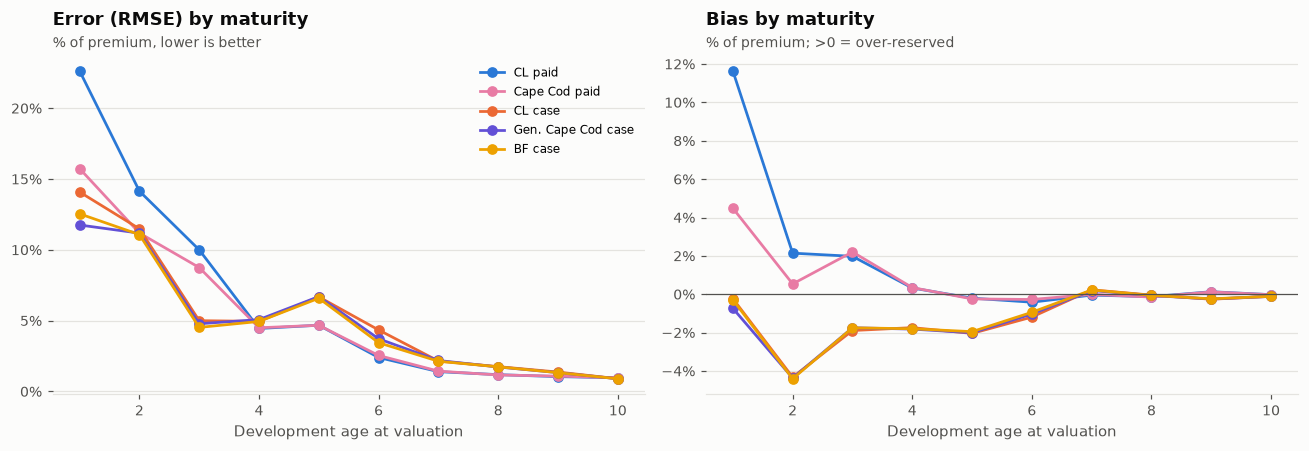

method,BF case,BF paid,Benktander case,CL case,CL paid,Cape Cod case,Cape Cod paid,ELR,Gen. Cape Cod case
age,,,,,,,,,
1,12.5%,16.1%,12.9%,14.1%,22.6%,12.0%,15.7%,18.0%,11.8%
2,11.1%,12.4%,11.5%,11.5%,14.1%,11.1%,11.2%,17.2%,11.2%
3,4.5%,8.0%,5.1%,5.0%,10.0%,4.7%,8.8%,11.8%,4.8%
4,4.9%,4.6%,4.9%,5.0%,4.4%,5.1%,4.5%,16.6%,5.1%
5,6.6%,4.8%,6.6%,6.7%,4.7%,6.7%,4.7%,16.1%,6.7%
6,3.4%,2.6%,4.4%,4.3%,2.4%,3.6%,2.5%,20.6%,3.7%
7,2.1%,1.4%,2.1%,2.1%,1.4%,2.2%,1.4%,7.5%,2.2%
8,1.7%,1.2%,1.8%,1.8%,1.2%,1.7%,1.2%,11.8%,1.7%
9,1.3%,1.1%,1.4%,1.4%,1.0%,1.3%,1.1%,11.0%,1.3%


In [3]:
err = B.error_by_age(bt)
show = ["CL paid", "Cape Cod paid", "CL case", "Gen. Cape Cod case", "BF case"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, metric, title, sub in [(axes[0], "rmse", "Error (RMSE) by maturity", "% of premium, lower is better"),
                               (axes[1], "bias", "Bias by maturity", "% of premium; >0 = over-reserved")]:
    piv = err.pivot(index="age", columns="method", values=metric)
    for m in show:
        ax.plot(piv.index, piv[m], marker="o", color=PL.COLOURS[m], label=m, lw=1.8)
    ax.set_title(title)
    PL.subtitle(ax, sub)
    ax.set_xlabel("Development age at valuation")
    PL.pct(ax)
    if metric == "bias":
        ax.axhline(0, color=PL.INK_2, lw=0.8)
axes[0].legend(fontsize=8)
fig.tight_layout()
PL.save(fig, "06_backtest_by_age")
plt.show()
err.pivot(index="age", columns="method", values="rmse").style.format("{:.1%}").background_gradient(axis=1, cmap="Blues")

In [4]:
print("Bias by age (% of premium)")
err.pivot(index="age", columns="method", values="bias").style.format("{:.1%}").background_gradient(axis=None, cmap="RdBu_r", vmin=-0.08, vmax=0.08)

Bias by age (% of premium)


method,BF case,BF paid,Benktander case,CL case,CL paid,Cape Cod case,Cape Cod paid,ELR,Gen. Cape Cod case
age,,,,,,,,,
1,-0.3%,2.7%,-0.6%,-0.2%,11.6%,-0.3%,4.5%,0.4%,-0.7%
2,-4.4%,-1.2%,-4.4%,-4.3%,2.1%,-4.3%,0.5%,-3.5%,-4.4%
3,-1.7%,1.4%,-1.9%,-1.9%,2.0%,-1.7%,2.2%,0.8%,-1.7%
4,-1.8%,0.2%,-1.7%,-1.7%,0.3%,-1.8%,0.3%,-0.7%,-1.8%
5,-1.9%,-0.3%,-2.0%,-2.0%,-0.2%,-2.0%,-0.2%,-2.7%,-2.0%
6,-0.9%,-0.4%,-1.2%,-1.2%,-0.4%,-1.0%,-0.3%,-1.7%,-1.0%
7,0.2%,-0.1%,0.2%,0.2%,-0.0%,0.2%,-0.0%,-2.6%,0.2%
8,-0.1%,-0.1%,-0.0%,-0.0%,-0.1%,-0.1%,-0.1%,-0.7%,-0.1%
9,-0.2%,0.1%,-0.3%,-0.3%,0.1%,-0.3%,0.1%,2.2%,-0.2%


**What the track record says:**

1. **Immature years (ages 1-2): case-based, prior-driven methods win.** Gen. Cape Cod case, Cape Cod case and BF case have the lowest error. **Paid CL is worst by a wide margin at age 1 and over-reserves on average by ~12% of premium.** That's the leverage problem from notebook 04 seen across 30 real companies.
2. **Developing years (3-5): the gap narrows.** Case methods are still slightly better at age 3; by ages 4-5 paid methods catch up and overtake.
3. **Mature years (6-10): paid methods are as good or better.** Case methods show a small but persistent **negative bias** (≈ −1 to −2% of premium at ages 2-6). Across this industry and period, case reserves on maturing claims tended to be **too low**, so case-based projections under-reserved.
4. **Paid and case errors have opposite signs** (paid high when young, case low when maturing). That's the classic argument for **blending** rather than picking one.
5. A pure **ELR** (industry prior, ignore the data) is poor at every age. A prior is a starting point, not an answer.

## 2. Total reserve error by company

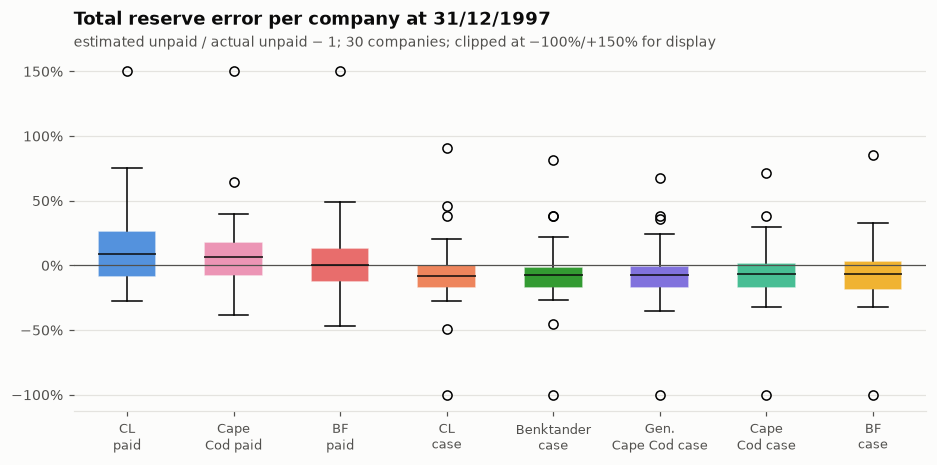

,mean,median,rmse,within_10pct
method,,,,
CL paid,14.6%,9.0%,40.9%,33.3%
Cape Cod paid,10.0%,6.6%,35.5%,30.0%
BF paid,7.2%,0.1%,41.3%,30.0%
CL case,-6.7%,-7.9%,34.2%,36.7%
Benktander case,-7.2%,-7.1%,33.2%,36.7%
Gen. Cape Cod case,-7.3%,-7.5%,31.4%,36.7%
Cape Cod case,-6.7%,-6.4%,31.3%,36.7%
BF case,-6.4%,-6.9%,30.5%,40.0%


In [5]:
tot = B.company_total_errors(bt)
order = ["CL paid", "Cape Cod paid", "BF paid", "CL case", "Benktander case", "Gen. Cape Cod case", "Cape Cod case", "BF case"]
fig, ax = plt.subplots(figsize=(10, 4.2))
data = [tot.loc[tot["method"] == m, "error_pct"].clip(-1, 1.5).values for m in order]
bp = ax.boxplot(data, vert=True, patch_artist=True, widths=0.55, showfliers=True, medianprops={"color": PL.INK})
for patch, m in zip(bp["boxes"], order):
    patch.set_facecolor(PL.COLOURS[m]); patch.set_alpha(0.8); patch.set_edgecolor(PL.SURFACE)
ax.axhline(0, color=PL.INK_2, lw=0.8)
ax.set_xticks(range(1, len(order) + 1), [o.replace(" ", "\n", 1) for o in order], fontsize=8.5)
ax.set_title("Total reserve error per company at 31/12/1997")
PL.subtitle(ax, "estimated unpaid / actual unpaid − 1; 30 companies; clipped at −100%/+150% for display")
PL.pct(ax)
PL.save(fig, "06_company_total_errors")
plt.show()
summary = tot.groupby("method")["error_pct"].agg(mean="mean", median="median", rmse=lambda x: np.sqrt((x**2).mean()),
                                                 within_10pct=lambda x: (x.abs() <= 0.10).mean())
summary.loc[order].style.format("{:.1%}")

At the company level, case-based methods are **typically 5-8% light** and paid CL is **typically ~10% heavy**, with wide dispersion either way. No single method lands within ±10% of the actual for more than 40% of companies. That's a sobering reminder of how hard reserving is on real data, and why a reserve review ends in a *range*.

## 3. Does blending actually help? An out-of-sample test

A natural rule is to weight each method by how accurate it has been at each maturity: **inverse mean squared error weights by maturity band**. But weights chosen on the same data used to judge them will always look good. So:

1. randomly split the 30 companies in half
2. learn the band weights on one half
3. apply them to the **other** half and measure the error
4. repeat 50 times and average

The candidate methods are kept to four, so the weights stay interpretable: chain ladder and Cape Cod (generalised, for case) on each basis.

In [6]:
methods = ["CL paid", "CL case", "Cape Cod paid", "Gen. Cape Cod case"]
oos = train_test_evaluation(bt, methods, seed=cfg.SEED, n_splits=50)
oos.style.format("{:.2%}")

,rmse,bias
method,,
Blended,6.00%,-0.28%
Gen. Cape Cod case,6.07%,-1.18%
CL case,6.70%,-1.12%
Cape Cod paid,6.83%,0.68%
CL paid,9.28%,1.57%


**The blend beats every single method out of sample**, and it almost removes the bias. Each single method carries a bias of roughly ±1% of premium per company-year; the blend's bias is close to zero, because paid and case errors partly cancel. The RMSE improvement is modest but consistent.

## 4. Evidence weights for the selection

Finally, the band weights estimated on **all 30 other companies**. These are the starting point for Penn National's selection in notebook 08:

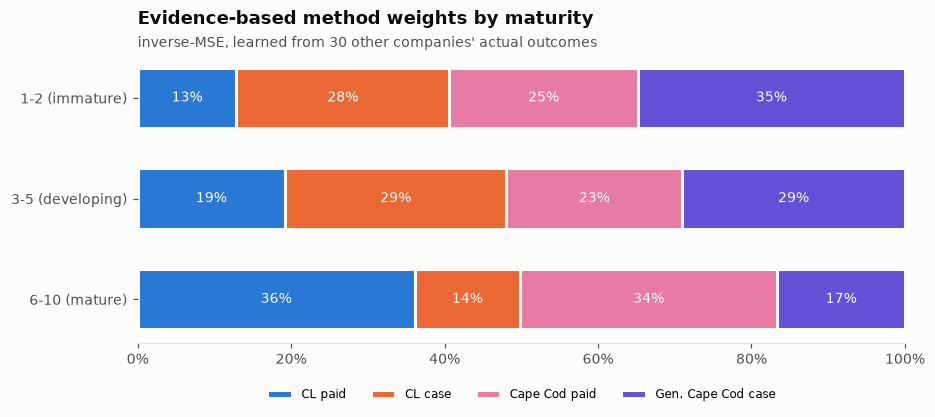

method,CL paid,CL case,Cape Cod paid,Gen. Cape Cod case
band,,,,
1-2 (immature),13%,28%,25%,35%
3-5 (developing),19%,29%,23%,29%
6-10 (mature),36%,14%,34%,17%


In [7]:
w = band_weights(bt, methods)
fig, ax = plt.subplots(figsize=(9, 3.4))
left = np.zeros(len(w))
for m in methods:
    ax.barh(range(len(w)), w[m], left=left, color=PL.COLOURS[m], label=m, edgecolor=PL.SURFACE, linewidth=2, height=0.6)
    for i, v in enumerate(w[m]):
        if v > 0.07:
            ax.text(left[i] + v / 2, i, f"{v:.0%}", ha="center", va="center", fontsize=9, color="white")
    left += w[m].values
ax.set_yticks(range(len(w)), w.index)
ax.invert_yaxis()
ax.grid(False)
ax.set_xlim(0, 1)
PL.pct(ax, axis="x")
ax.set_title("Evidence-based method weights by maturity")
PL.subtitle(ax, "inverse-MSE, learned from 30 other companies' actual outcomes")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=8)
PL.save(fig, "06_evidence_weights")
plt.show()
w.style.format("{:.0%}")

The pattern matches actuarial intuition, but now it's quantified: **case-based methods carry ~60-70% of the weight for immature and developing years**, flipping to **~70% paid for mature years**.

## Caveats

* **Hindsight across companies, not within one.** At 31/12/1997 nobody had these companies' 1998-2007 outcomes. In practice the same evidence comes from the company's own past reserve reviews (actual vs expected) and published industry studies. The cross-company test stands in for that track record; it isn't something an actuary could have computed in 1997.
* **One period, one line.** The case-reserve weakness seen here belongs to US commercial auto in the 1990s soft market. Weights shouldn't be carried to another line or era without fresh evidence.
* **Mechanical methods.** A careful actuary would improve on each method with judgement. The test compares methods on a level playing field rather than estimating the best achievable accuracy.
* **"Actual" is itself an estimate:** reported incurred at age 10 still includes a little IBNR (~0.4% of paid for the industry, notebook 03).

## Conclusions → next steps

* Prior-driven, case-based methods are best for immature years; paid methods for mature ones. Paid CL at age 1-2 is the worst estimator tested.
* Paid and case methods err in opposite directions, so **a maturity-weighted blend is more accurate out of sample than any single method**.
* These evidence weights feed directly into the selection in notebook 08.